<a href="https://colab.research.google.com/github/Fespinoza1477/A04-Custering/blob/main/notebook_6_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Fabrizzio Espinoza

**Date:** 10/14/2026

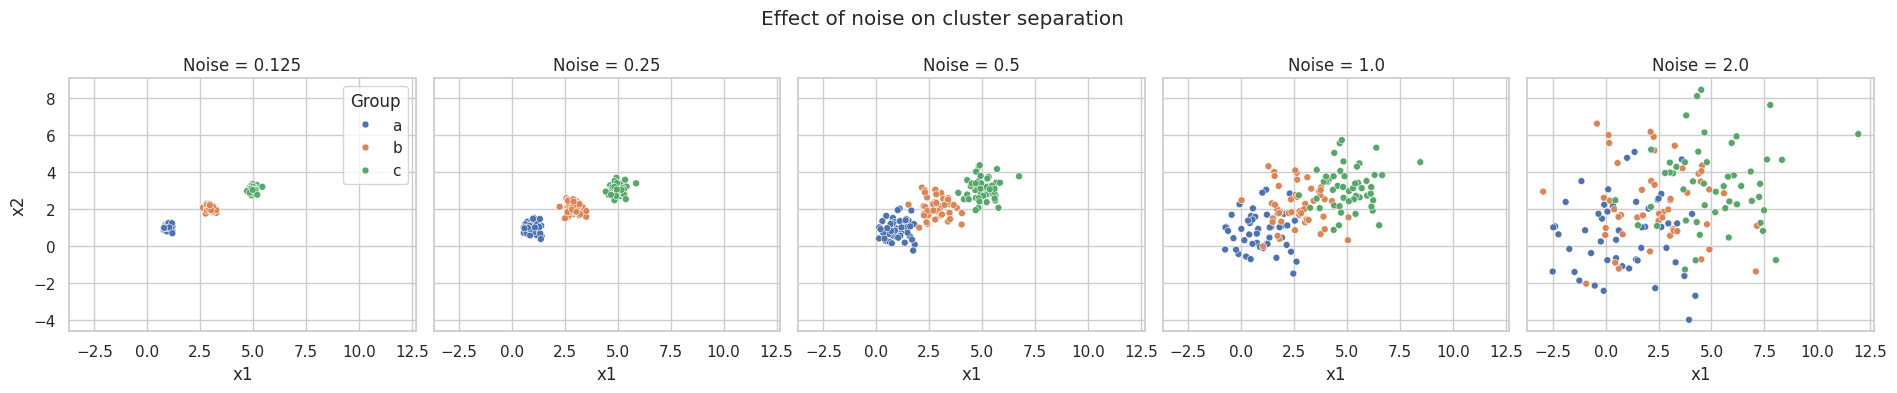

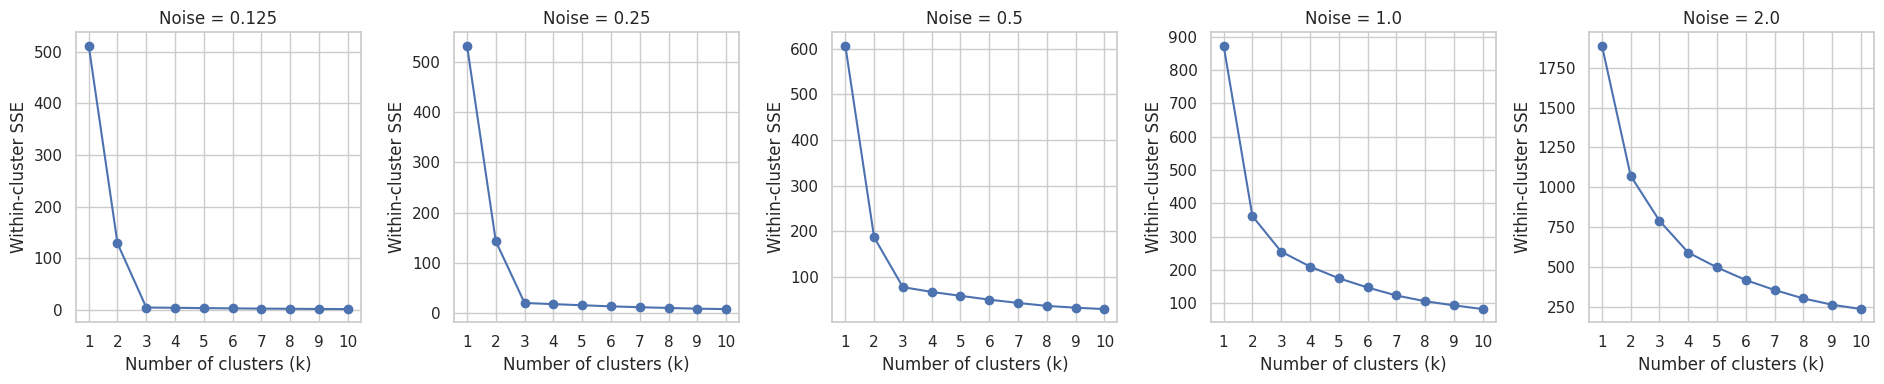

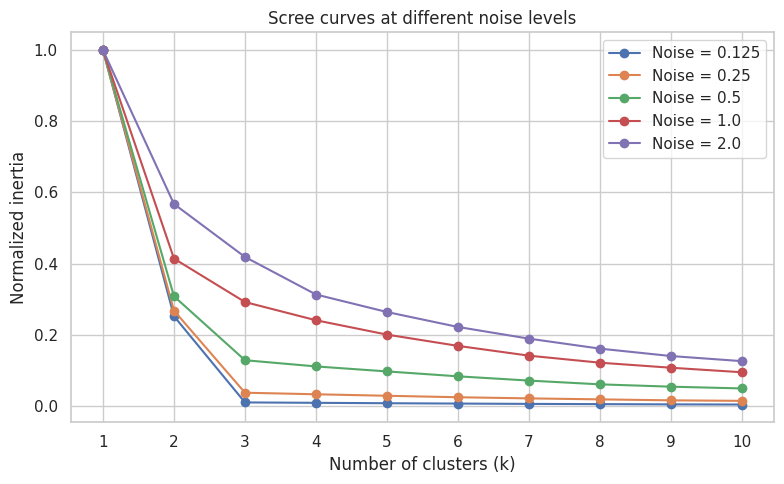

Number of countries: 148
Duplicate country names: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                       

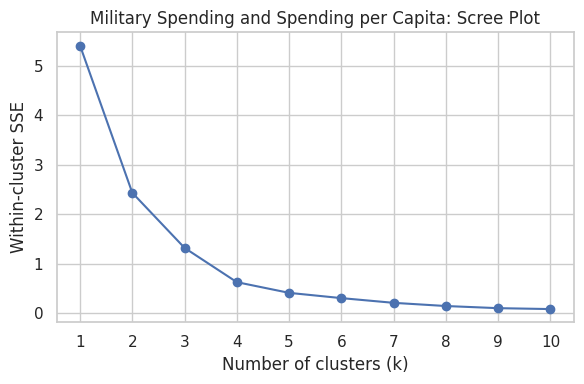

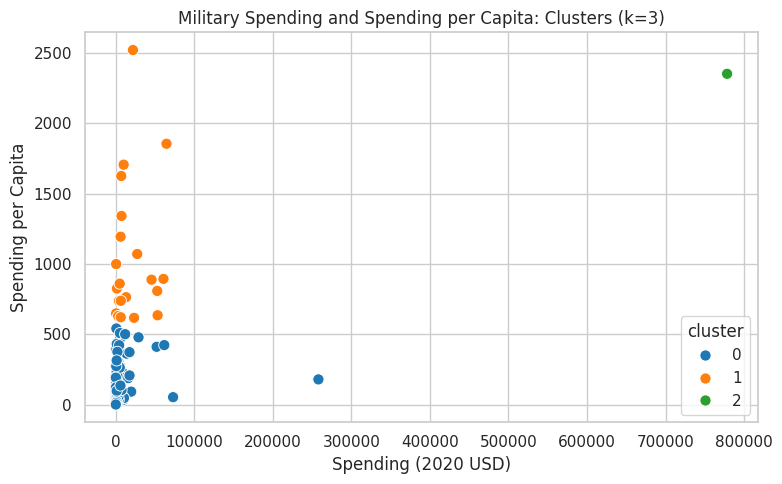


Countries per cluster:
cluster
0    126
1     21
2      1
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                                 \
                      count        mean        std         min         25%   
cluster                                                                      
0                     126.0    5943.346  24858.961       8.622     162.762   
1                      21.0   19975.991  21749.737     405.790    4980.428   
2                       1.0  778397.200        NaN  778397.200  778397.200   

                                           Spending per Capita            \
                50%         75%        max               count      mean   
cluster                                                                    
0           580.758    3225.333  257973.43               126.0   122.035   
1          7269.880   27300.895   64558.40                21.0  1046.434   
2        778397.200  778397.200  778397.20                 1.0  2351.632   

                                                                    
             std       min       25%       50%       75%       max  
cluster                                                             
0        140.041     0.580    18.506    58.809   188.249   541.155  
1        501.632   616.854   737.690   859.881  1193.599  2520.399  
2            NaN  2351.632  2351.632  2351.632  2351.632  2351.632


Mean values by cluster:


,Spending (2020 USD),Spending per Capita
cluster,,
0,5943.346,122.035
1,19975.991,1046.434
2,778397.200,2351.632



United States:


,Country,Spending (2020 USD),Spending per Capita,cluster
5540,United States of America,778397.2,2351.631858,2


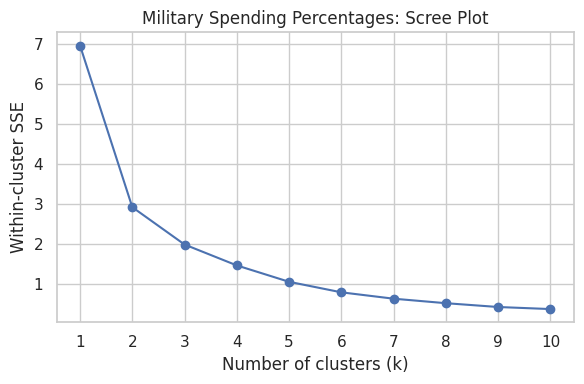

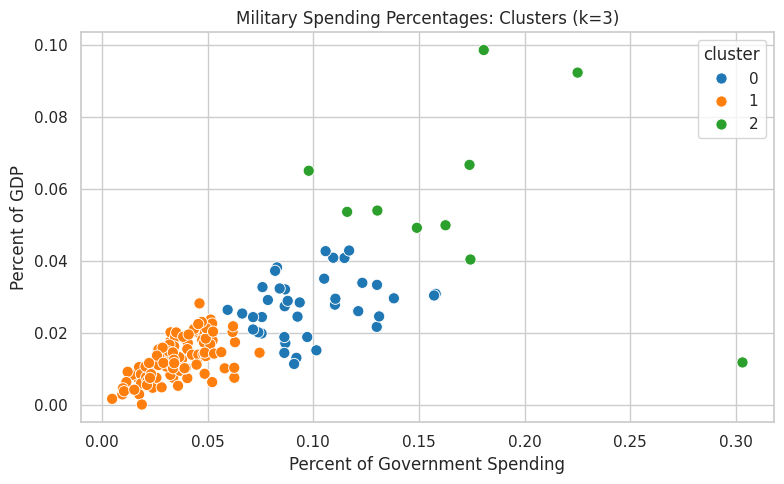


Countries per cluster:
cluster
0    39
1    99
2    10
Name: count, dtype: int64

Descriptive statistics by cluster:


Percent of Government Spending                                     \
                                 count   mean    std    min    25%    50%   
cluster                                                                     
0                                 39.0  0.099  0.024  0.060  0.082  0.092   
1                                 99.0  0.036  0.015  0.005  0.026  0.034   
2                                 10.0  0.171  0.059  0.098  0.135  0.168   

                      Percent of GDP                                     \
           75%    max          count   mean    std    min    25%    50%   
cluster                                                                   
0        0.113  0.158           39.0  0.027  0.008  0.011  0.021  0.028   
1        0.047  0.075           99.0  0.013  0.006  0.000  0.008  0.013   
2        0.179  0.303           10.0  0.058  0.025  0.012  0.049  0.054   

                       
           75%    max  
cluster                
0        0.032  0.043  
1        0.017  0.028  
2        0.066  0.098


Mean values by cluster:


,Percent of Government Spending,Percent of GDP
cluster,,
0,0.099,0.027
1,0.036,0.013
2,0.171,0.058



United States:


,Country,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,0.081976,0.037179,0


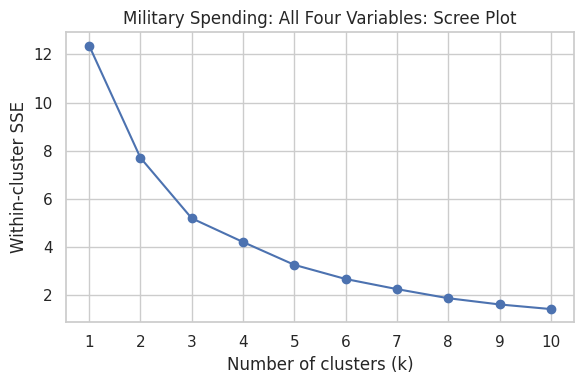

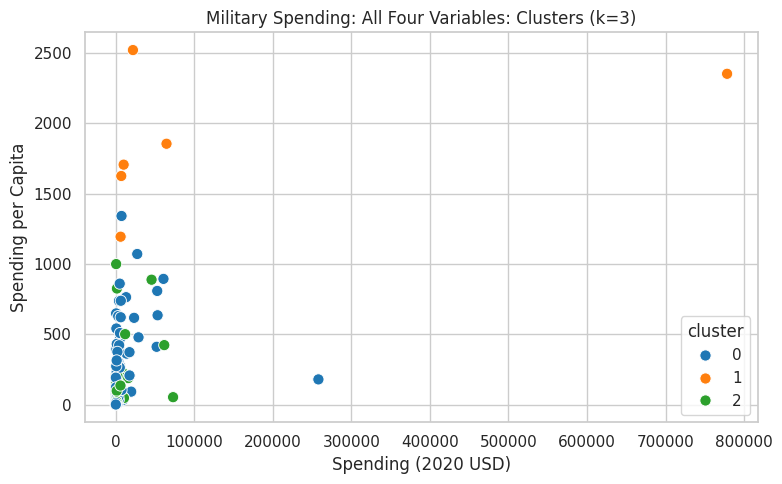


Countries per cluster:
cluster
0    111
1      6
2     31
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                              \
                      count        mean         std       min       25%   
cluster                                                                   
0                     111.0    7086.473   26479.380     8.622   130.010   
1                       6.0  147964.582  309635.190  6095.709  7700.425   
2                      31.0    8786.087   17901.909   162.373   467.788   

                                          Spending per Capita            ...  \
               50%        75%         max               count      mean  ...   
cluster                                                                  ...   
0          567.651   3910.107  257973.430               111.0   196.927  ...   
1        15897.571  53872.942  778397.200                 6.0  1875.151  ...   
2         1404.787   7739.166   72937.064                31.0   212.689  ...   

        Percent of Government Spending        Percent of GDP                \
                                   75%    max          count   mean    std   
cluster                                                                      
0                                0.051  0.092          111.0  0.013  0.006   
1                                0.165  0.225            6.0  0.063  0.028   
2                                0.135  0.303           31.0  0.033  0.011   

                                            
           min    25%    50%    75%    max  
cluster                                     
0        0.000  0.009  0.014  0.018  0.028  
1        0.029  0.041  0.059  0.085  0.098  
2        0.012  0.028  0.032  0.041  0.067  

[3 rows x 32 columns]


Mean values by cluster:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033



United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


In [1]:
# Your Phase 1 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0, :], "x2": X1[1, :], "group": "a"
    })
    gdf2 = pd.DataFrame({
        "x1": X2[0, :], "x2": X2[1, :], "group": "b"
    })
    gdf3 = pd.DataFrame({
        "x1": X3[0, :], "x2": X3[1, :], "group": "c"
    })

    return pd.concat([gdf1, gdf2, gdf3], ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
#1.2
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

fig, axes = plt.subplots(
    1, 5, figsize=(19, 4), sharex=True, sharey=True
)

for i, (noise, data) in enumerate(datasets.items()):
    sns.scatterplot(
        data=data,
        x="x1",
        y="x2",
        hue="group",
        ax=axes[i],
        s=25
    )
    axes[i].set_title(f"Noise = {noise}")

    if i > 0:
        axes[i].get_legend().remove()

axes[0].legend(title="Group")
fig.suptitle("Effect of noise on cluster separation")
plt.tight_layout()
plt.show()
#As the noise increases, the three clusters become less visually distinct. At a standard deviation of 0.125, the groups are compact and clearly separated. At 0.25, they remain relatively distinct, while at 0.5, the points spread out and begin to overlap. At 1.0, there is considerably more overlap, making it harder to distinguish the groups. At 2.0, the points overlap heavily, so the original three groups are much less apparent. This demonstrates that increasing noise makes it more difficult for a clustering algorithm to identify the underlying group structure.
#1.3
K_RANGE = range(1, 11)
inertias_by_noise = {}

for noise, data in datasets.items():
    X = data[["x1", "x2"]].to_numpy()
    inertias = []

    for k in K_RANGE:
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=100
        )
        model.fit(X)
        inertias.append(model.inertia_)

    inertias_by_noise[noise] = inertias
fig, axes = plt.subplots(1, 5, figsize=(19, 4))

for ax, (noise, inertias) in zip(
    axes, inertias_by_noise.items()
):
    ax.plot(list(K_RANGE), inertias, marker="o")
    ax.set_title(f"Noise = {noise}")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Within-cluster SSE")
    ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))

for noise, inertias in inertias_by_noise.items():
    normalized = np.array(inertias) / inertias[0]
    plt.plot(
        list(K_RANGE),
        normalized,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.xlabel("Number of clusters (k)")
plt.ylabel("Normalized inertia")
plt.title("Scree curves at different noise levels")
plt.xticks(list(K_RANGE))
plt.legend()
plt.tight_layout()
plt.show()
#Iniertia decreases as k increases bcause adding more centroids allows the algorithm to fit the observations more closely. At low noise levels, the scree plot generally has a clearer bend around k = 3, which is consistent with the three groups used to generate the data. As noise increases, the points spread farther from their original centers and overlap more, making the elbow less distinct. Consequently, selecting the optimal k becomes more subjective. The normalized plot helps compare the shapes of the curves even though their absolute inertia values differ.
#1.4
#The elbow method involves plotting inertia against the number of clusters and identifying the point where increasing k produces diminishing improvements. For ex, moving from 1 to 3 clusters can substantially reduce within-cluster variation when the data contains three distinct groups. Adding many more clusters may reduce the variation further, but each additional cluster provides a smaller improvement and makes the model more complex. In this simulation, k = 3 is a natural reference because the data was generated from three centers. However, as noise increases, the group overlap and the elbow becomes less obvious. The elbow method is therefor a useful heuristic rather than a guarantee of the uniquely correct number of clusters.
#2.1
import pandas as pd
import numpy as np

DATA_PATH = "/content/SIPRI Military Expenditure Database.csv"

sipri = pd.read_csv(DATA_PATH)

df2020 = sipri[sipri["Year"] == 2020].dropna().copy()

variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

print("Number of countries:", len(df2020))
print("Duplicate country names:",
      df2020["Country"].duplicated().sum())

print(df2020[variables].dtypes)
print(df2020[variables].describe())
#Filtering the spllied dataset to 2020 and removing rows with missing values leaves 148 as expected. The 4 variables used for clustering are already numeric, and there are no duplicate country names among the remaining records. The index column is only an identifier and should not be used as a clustering variable. The year column should also be excluded because every observation is from 2020. No additional mandatory cleaning is apparent from these checks. However, the percentage variables should be interpreted carefully. In this dataset, values are stored as fractions.
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

def cluster_analysis(data, selected_vars, k=3, title="K-means"):

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[selected_vars])


    inertias = []

    for candidate_k in range(1, 11):
        model = KMeans(
            n_clusters=candidate_k,
            n_init=50,
            random_state=100
        )
        model.fit(X_scaled)
        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, 11), inertias, marker="o")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster SSE")
    plt.title(f"{title}: Scree Plot")
    plt.xticks(range(1, 11))
    plt.tight_layout()
    plt.show()


    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=100
    )

    result = data[["Country"] + selected_vars].copy()
    result["cluster"] = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=result,
        x=selected_vars[0],
        y=selected_vars[1],
        hue="cluster",
        palette="tab10",
        s=65
    )
    plt.title(f"{title}: Clusters (k={k})")
    plt.tight_layout()
    plt.show()

    print("\nCountries per cluster:")
    print(result["cluster"].value_counts().sort_index())

    print("\nDescriptive statistics by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .describe()
        .round(3)
    )

    print("\nMean values by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .mean()
        .round(3)
    )

    # United States
    print("\nUnited States:")
    display(
        result[
            result["Country"].str.contains(
                "United States", case=False, na=False
            )
        ]
    )

    return result, model, scaler
#2.2
vars_part2 = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

clusters_part2, model_part2, scaler_part2 = cluster_analysis(
    df2020,
    vars_part2,
    k=3,
    title="Military Spending and Spending per Capita"
)
# The scree plot shows a substantial reduction in inertia as the number of clusters initially increases, followed by progressively smaller improvements. I use k = 3 as a starting choice for comparing the three analyses, although the elbow method is subjective and another value may also be denfible. With this choice, the US is the only country in cluster 2. Its total military expenditure is approximately 778,397 million 2020 USD, and its spending per capita is approx 2,351.63 USD. The other 2 clusters contain countries with generally lower expenditure. This indicated that the US is an extremem outlier in absolute military spending, while the remaining countries are grouped according to differences in total and per-capita expenditure.
#2.3
vars_part3 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part3, model_part3, scaler_part3 = cluster_analysis(
    df2020,
    vars_part3,
    k=3,
    title="Military Spending Percentages"
)
#The results differ from Part 2 because these variables measure the relative importance of military expenditure rather than the absoulte amount spent. With k = 3, the clusters contain 99, 39, and 1 countries. Their median percentages of government spending and GDP are Approx 3.4%, 1.3%, 9.2%, 2.8%, 16.8%, and 5.4%. The US belongs to cluster 0 in this run, with military expenditure equal to approx 8.2 of government spending and 3.72% of GDP. These results show that countries spending large amounts in absolute terms do not necessarily devote the largest proportion of their national resources to the military. Conversely, a country with a smaller military budget may still have a relatively high military burden.
#2.4
all_variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part4, model_part4, scaler_part4 = cluster_analysis(
    df2020,
    all_variables,
    k=3,
    title="Military Spending: All Four Variables"
)
#Using all 4 variables combines information about absolute military expenditure, per-capita expenditure, and the proportion of national resources devoted to the military. With k = 3, the US belongs to cluster 1, which contains six countries and has relatively high spending measures. The remaining countries are divided into groups with generally lower absolute expenditure and differing relative spenidng levels. This differs form Parts 2 and 3 because the algorithm now considers all four measures simultaneously. Min-max normalization places each feature on a comparable 0 to 1 scla,e but extreme observations and correlations between bariables can still influence the clustering. Therefore, using all 4 variables provides a broader view, but it does not automatically make the resulting clusters better.
#2.5
#Yes, k-means identified useful patterns in the 2020 military expenditure data. When total spending and spending per capita were used, the US was separated from the other countries because of its exceptionally high military expenditure. When the percentage variables were used, the clusters instead distinguished countries that devoted relatively small, moderate, or large shares of their resources to the military. using all 4 variables combined these different perspectives and produced a different grouping. However, k-means depends on the selected number of clusters, the scaling of variables, and the influence of outliers. CLuster numbers also have no inherent ranking or meaning. Therefore, the algorithm is useful for exploring similarities between countries, but the resulting clusters should not be treated as definitive categories or explanations of why countries spend what they do.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 09b804088fa419e0e7a2706eeb2e4d210da11506
- **AI tool and model used:** Gemini Pro 3.1

### *Prompts used

1. Of the following code that I have, is there anything I can change to make my data look more presentable and answer the question.
2. For my written answers, is it answering the question and providing enough information to support my answer.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q2.1 Military expenditure data (Spending (2020 USD) and Spending per Capita) contains massive right-skew and extreme outliers (such as the United States).
Action: When answering whether further cleaning is required, note that while max-min normalization bounds the data between 0 and 1, extreme outliers will compress nearly all observations into a tight cluster near zero. Consider mentioning or testing a logarithmic transformation (e.g., np.log1p()) before scaling if the standard clusters are too obscured by outliers.

Presenting Groupby Summary Tables (Q2.2)
Using raw .groupby('cluster').describe() generates a wide, multi-index table that is difficult to read.
Action: Refine your table output by selecting key summary metrics, rounding decimals, or transposing the dataframe for readability

Enhancing Visualization Readability (Q1 & Q2)
Scree plots and scatter plots require clear formatting to definitively identify the "elbow" and cluster groupings.   
IPYNB
Action: Add explicit figure sizes, grid lines, titles, and labeled axes to all plot

2.  Specific Data Evidence: In Q2.2 and Q2.3, you cite specific findings (e.g., the U.S. spending totals and percentages) rather than making vague general statements.
Conceptual Clarity: Your explanation of the elbow method (Q1.4) and the distinction between absolute spending (Part 2) versus relative economic burden (Part 3) directly demonstrates conceptual understanding.
Complete Coverage: Every sub-question (from Q1.1 through Q2.5) is accounted for.

Typos to Clean Up: There are a few minor typos in your comments/answers that you may want to correct before final submission (e.g., "Iniertia" instead of Inertia, "therefor" instead of therefore, "spllied" instead of supplied, "extremem" instead of extreme, and "denfible" instead of defensible).
Formatting: Ensure that when these comments are transferred into markdown answer cells (or written up in your final submission), key terms like k=3 and variable names are formatted cleanly with markdown/LaTeX for readability.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Some of my code is able to make the graphs and information be seen, but might not be ideal to do much analysis on. I looked at the graphs between the Phase 1 and Phase 2 and saw a major improvement on the readability of the data and helps to answer my questions more confidently/|
| 2 | Accept | Apart from spelling errors, It helps make sure that I am answering the question without adding too much filler and gets to the point with the language that I have written. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

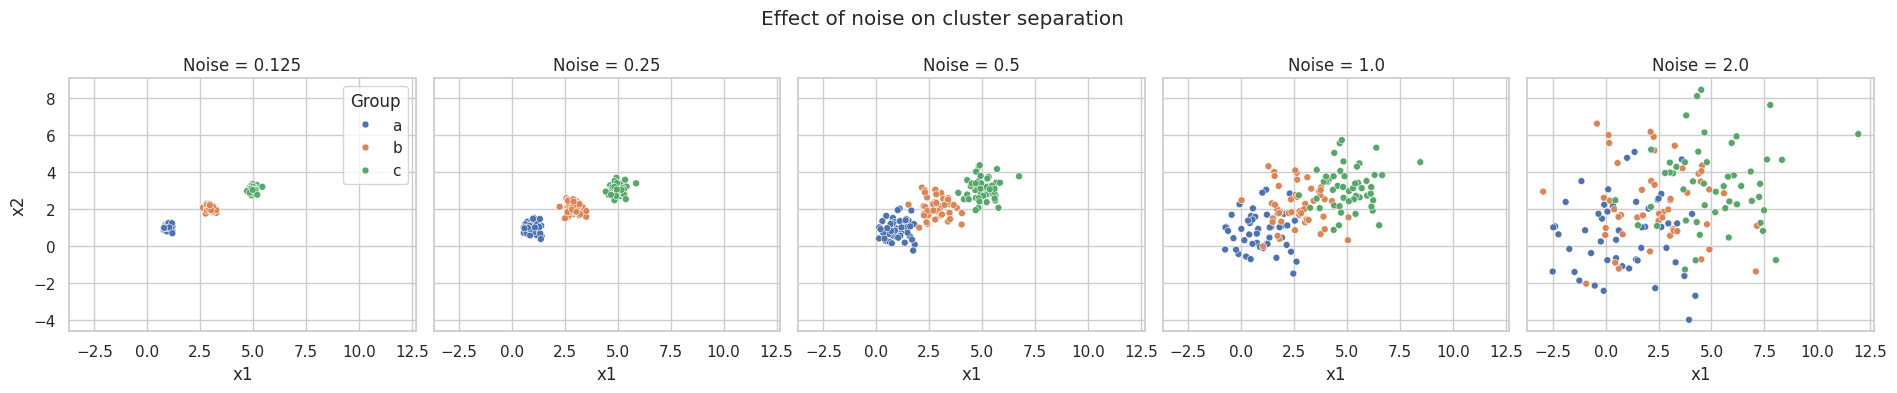

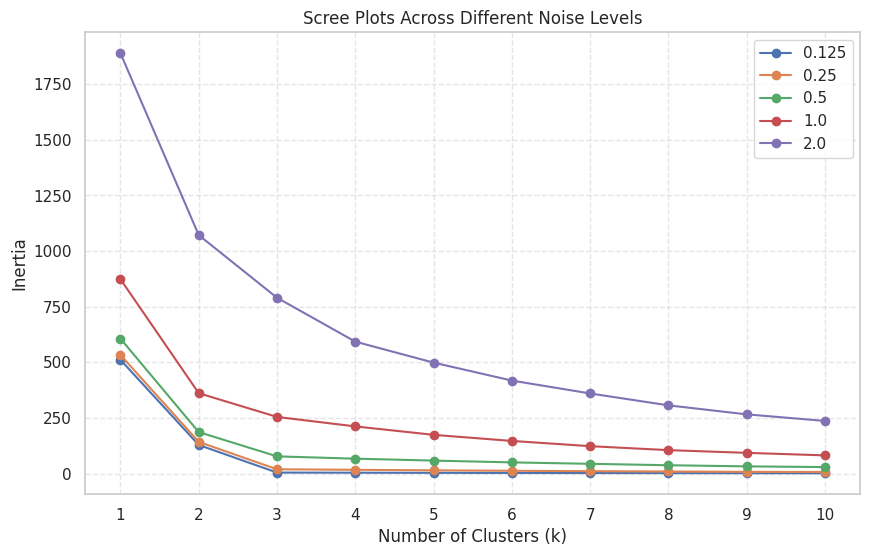

Number of countries: 148
Duplicate country names: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                       

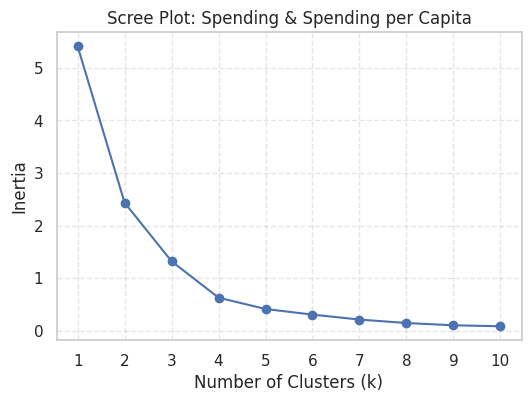

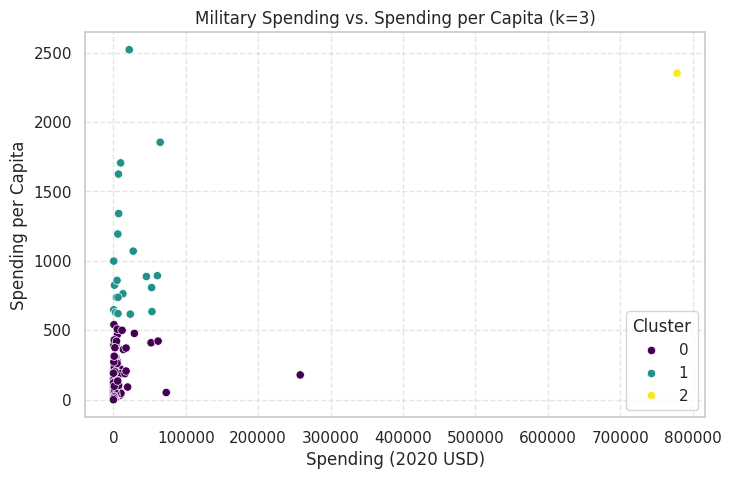

Describe Table by Cluster:


Cluster_Q2                         0         1          2
Spending (2020 USD) count     126.00     21.00       1.00
                    mean     5943.35  19975.99  778397.20
                    std     24858.96  21749.74        NaN
                    min         8.62    405.79  778397.20
                    25%       162.76   4980.43  778397.20
                    50%       580.76   7269.88  778397.20
                    75%      3225.33  27300.89  778397.20
                    max    257973.43  64558.40  778397.20
Spending per Capita count     126.00     21.00       1.00
                    mean      122.03   1046.43    2351.63
                    std       140.04    501.63        NaN
                    min         0.58    616.85    2351.63
                    25%        18.51    737.69    2351.63
                    50%        58.81    859.88    2351.63
                    75%       188.25   1193.60    2351.63
                    max       541.15   2520.40    2351.63


United States Cluster Membership:


,Cluster_Q2,Spending (2020 USD),Spending per Capita


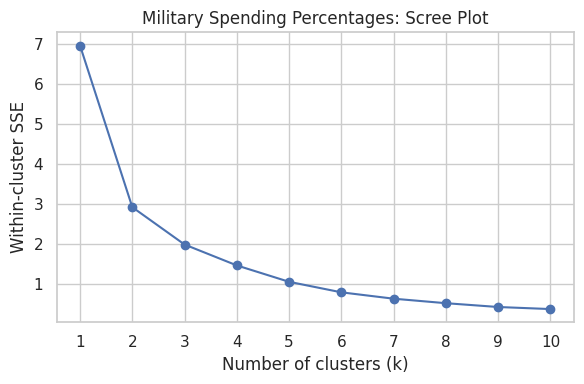

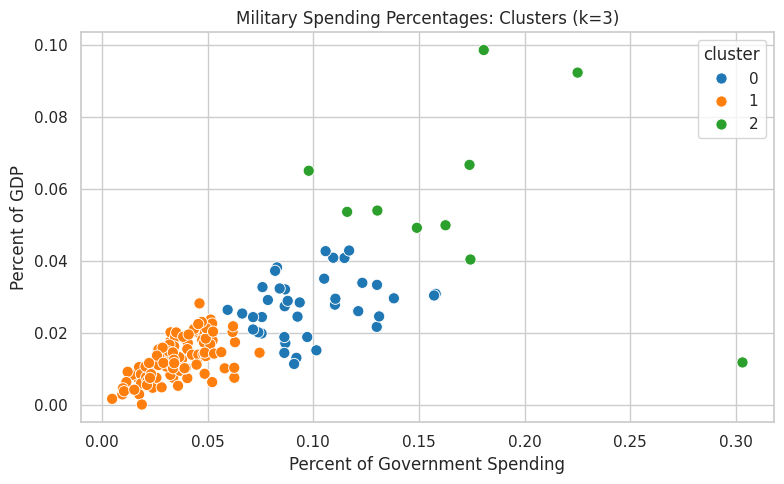


Countries per cluster:
cluster
0    39
1    99
2    10
Name: count, dtype: int64

Descriptive statistics by cluster:


Percent of Government Spending                                     \
                                 count   mean    std    min    25%    50%   
cluster                                                                     
0                                 39.0  0.099  0.024  0.060  0.082  0.092   
1                                 99.0  0.036  0.015  0.005  0.026  0.034   
2                                 10.0  0.171  0.059  0.098  0.135  0.168   

                      Percent of GDP                                     \
           75%    max          count   mean    std    min    25%    50%   
cluster                                                                   
0        0.113  0.158           39.0  0.027  0.008  0.011  0.021  0.028   
1        0.047  0.075           99.0  0.013  0.006  0.000  0.008  0.013   
2        0.179  0.303           10.0  0.058  0.025  0.012  0.049  0.054   

                       
           75%    max  
cluster                
0        0.032  0.043  
1        0.017  0.028  
2        0.066  0.098


Mean values by cluster:


,Percent of Government Spending,Percent of GDP
cluster,,
0,0.099,0.027
1,0.036,0.013
2,0.171,0.058



United States:


,Country,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,0.081976,0.037179,0


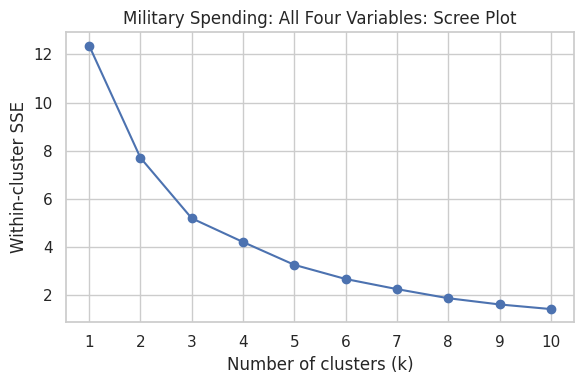

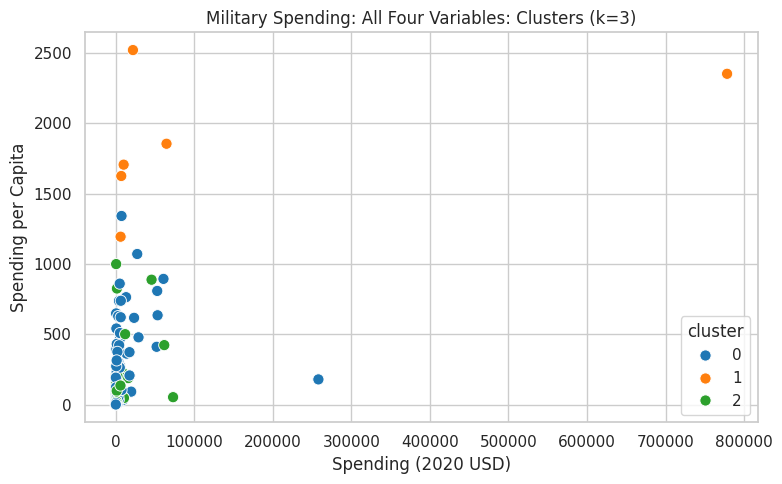


Countries per cluster:
cluster
0    111
1      6
2     31
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                              \
                      count        mean         std       min       25%   
cluster                                                                   
0                     111.0    7086.473   26479.380     8.622   130.010   
1                       6.0  147964.582  309635.190  6095.709  7700.425   
2                      31.0    8786.087   17901.909   162.373   467.788   

                                          Spending per Capita            ...  \
               50%        75%         max               count      mean  ...   
cluster                                                                  ...   
0          567.651   3910.107  257973.430               111.0   196.927  ...   
1        15897.571  53872.942  778397.200                 6.0  1875.151  ...   
2         1404.787   7739.166   72937.064                31.0   212.689  ...   

        Percent of Government Spending        Percent of GDP                \
                                   75%    max          count   mean    std   
cluster                                                                      
0                                0.051  0.092          111.0  0.013  0.006   
1                                0.165  0.225            6.0  0.063  0.028   
2                                0.135  0.303           31.0  0.033  0.011   

                                            
           min    25%    50%    75%    max  
cluster                                     
0        0.000  0.009  0.014  0.018  0.028  
1        0.029  0.041  0.059  0.085  0.098  
2        0.012  0.028  0.032  0.041  0.067  

[3 rows x 32 columns]


Mean values by cluster:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033



United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


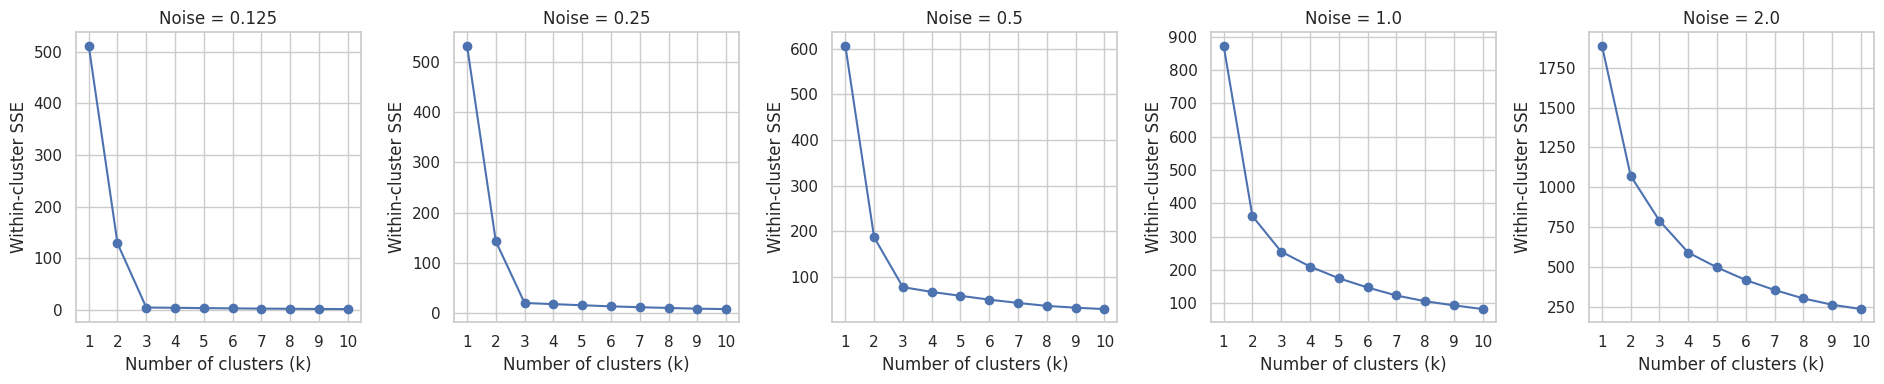

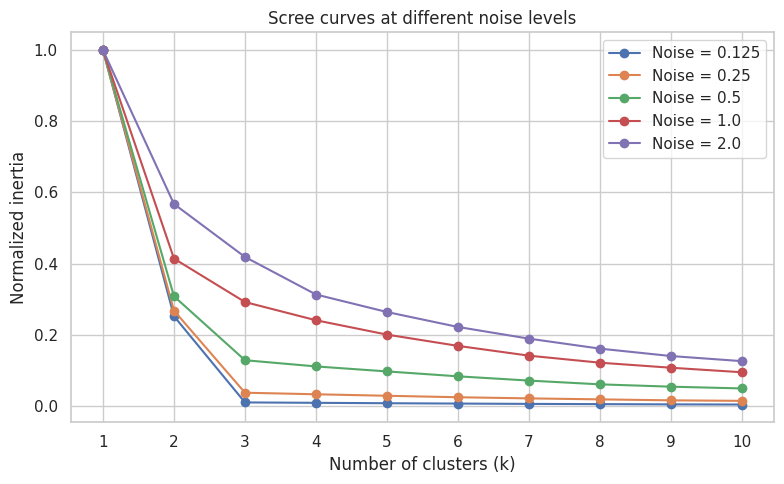

Number of countries: 148
Duplicate country names: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                       

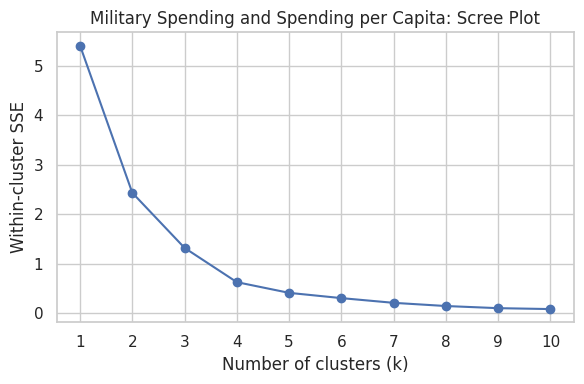

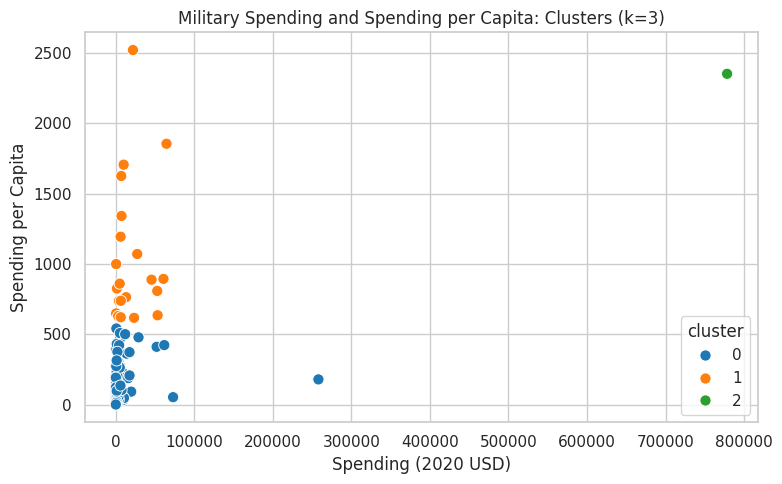


Countries per cluster:
cluster
0    126
1     21
2      1
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                                 \
                      count        mean        std         min         25%   
cluster                                                                      
0                     126.0    5943.346  24858.961       8.622     162.762   
1                      21.0   19975.991  21749.737     405.790    4980.428   
2                       1.0  778397.200        NaN  778397.200  778397.200   

                                           Spending per Capita            \
                50%         75%        max               count      mean   
cluster                                                                    
0           580.758    3225.333  257973.43               126.0   122.035   
1          7269.880   27300.895   64558.40                21.0  1046.434   
2        778397.200  778397.200  778397.20                 1.0  2351.632   

                                                                    
             std       min       25%       50%       75%       max  
cluster                                                             
0        140.041     0.580    18.506    58.809   188.249   541.155  
1        501.632   616.854   737.690   859.881  1193.599  2520.399  
2            NaN  2351.632  2351.632  2351.632  2351.632  2351.632


Mean values by cluster:


,Spending (2020 USD),Spending per Capita
cluster,,
0,5943.346,122.035
1,19975.991,1046.434
2,778397.200,2351.632



United States:


,Country,Spending (2020 USD),Spending per Capita,cluster
5540,United States of America,778397.2,2351.631858,2


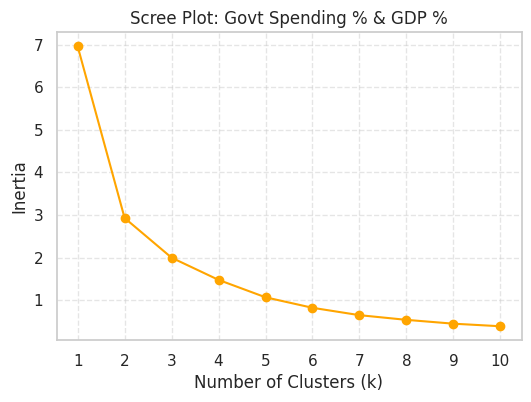

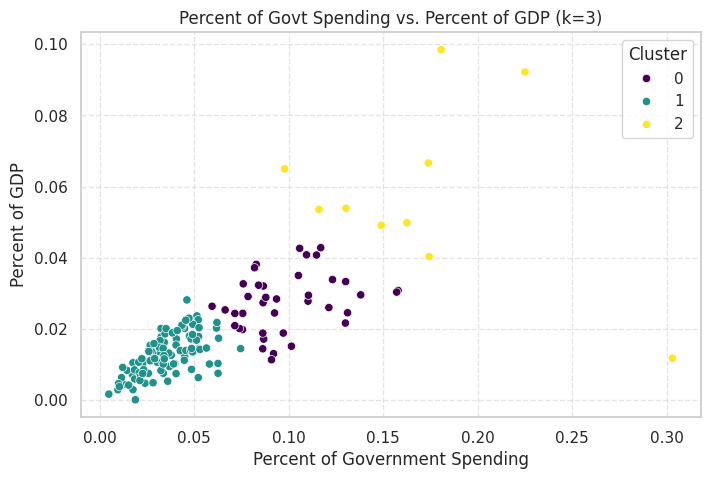

Describe Table by Cluster:


Cluster_Q3                                  0        1        2
Percent of Government Spending count  39.0000  99.0000  10.0000
                               mean    0.0987   0.0358   0.1713
                               std     0.0241   0.0145   0.0587
                               min     0.0595   0.0049   0.0979
                               25%     0.0824   0.0259   0.1350
                               50%     0.0920   0.0343   0.1682
                               75%     0.1126   0.0474   0.1791
                               max     0.1579   0.0746   0.3030
Percent of GDP                 count  39.0000  99.0000  10.0000
                               mean    0.0274   0.0127   0.0581
                               std     0.0082   0.0057   0.0249
                               min     0.0113   0.0001   0.0117
                               25%     0.0213   0.0084   0.0493
                               50%     0.0278   0.0132   0.0537
                               75%     0.0325   0.0168   0.0662
                               max     0.0428   0.0281   0.0985


United States Cluster Membership:


,Cluster_Q3,Percent of Government Spending,Percent of GDP


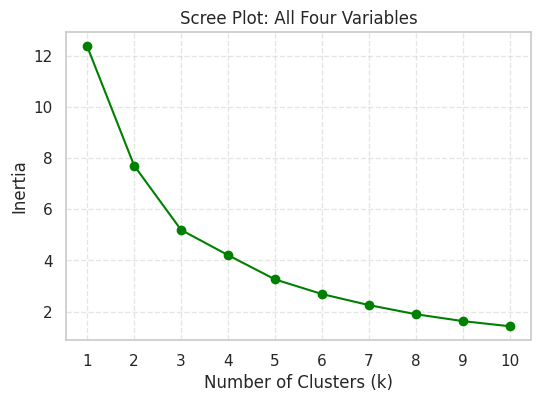

Cluster Profiles (Mean Values):


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
Cluster_Q4,,,,
0,8786.0866,212.6891,0.1230,0.0335
1,147964.5820,1875.1508,0.1354,0.0626
2,7086.4728,196.9268,0.0404,0.0134



United States Cluster Membership:


,Cluster_Q4,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP


In [3]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0, :], "x2": X1[1, :], "group": "a"
    })
    gdf2 = pd.DataFrame({
        "x1": X2[0, :], "x2": X2[1, :], "group": "b"
    })
    gdf3 = pd.DataFrame({
        "x1": X3[0, :], "x2": X3[1, :], "group": "c"
    })

    return pd.concat([gdf1, gdf2, gdf3], ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
#1.2
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

fig, axes = plt.subplots(
    1, 5, figsize=(19, 4), sharex=True, sharey=True
)

for i, (noise, data) in enumerate(datasets.items()):
    sns.scatterplot(
        data=data,
        x="x1",
        y="x2",
        hue="group",
        ax=axes[i],
        s=25
    )
    axes[i].set_title(f"Noise = {noise}")

    if i > 0:
        axes[i].get_legend().remove()

axes[0].legend(title="Group")
fig.suptitle("Effect of noise on cluster separation")
plt.tight_layout()
plt.show()
#As noise increases from 0.125 to 2.0, the three clusters become progressively less visually distinct. At a standard deviation of 0.125, the groups are compact and clearly separated. By 0.5, the points spread out and begin to overlap. At 2.0, the points overlap heavily, completely obscuring the original three groups. This demonstrates that increased noise makes it significantly more difficult for clustering algorithms to identify underlying data structures
#1.3
from sklearn.cluster import KMeans

plt.figure(figsize=(10, 6))
k_values = range(1, 11)

for title, data in datasets.items():
    X = data[['x1', 'x2']]
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    # Plot each line on the same canvas
    plt.plot(k_values, inertias, marker='o', label=title)

plt.title('Scree Plots Across Different Noise Levels')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
#At low noise levels, the scree plot exhibits a distinct "elbow" or bend at k=3, perfectly aligning with the three distinct groups used to generate the data. As noise increases, the points spread further from their centroids and overlap, which smooths out the scree curve and makes the elbow significantly less distinct. Consequently, a higher noise level makes definitively selecting an optimal k much more subjective.
#1.4
#The elbow method identifies the point where increasing k yields diminishing returns in reducing within-cluster variation (inertia). For example, moving from 1 to 3 clusters substantially reduces variation because the data was generated from three distinct centers. Adding more clusters beyond 3 reduces variation only marginally while overcomplicating the model. As noise increases and groups overlap, this inflection point becomes less obvious, illustrating that the elbow method is a useful heuristic rather than a definitive guarantee for finding the correct number of clusters.
#2.1
import pandas as pd
import numpy as np

DATA_PATH = "/content/SIPRI Military Expenditure Database.csv"

sipri = pd.read_csv(DATA_PATH)

df2020 = sipri[sipri["Year"] == 2020].dropna().copy()

variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

print("Number of countries:", len(df2020))
print("Duplicate country names:",
      df2020["Country"].duplicated().sum())

print(df2020[variables].dtypes)
print(df2020[variables].describe())
#Filtering the dataset to 2020 and removing rows with missing values leaves exactly 148 countries. The four target variables are already numeric, and there are no duplicate country names, so no additional mandatory cleaning is required. The 'Index' and 'Year' columns should be excluded from the model. However, because extreme outliers (like the United States) exist in the absolute spending data, applying a logarithmic transformation prior to max-min normalization could help prevent the majority of the data from being compressed near zero.
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

def cluster_analysis(data, selected_vars, k=3, title="K-means"):

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[selected_vars])


    inertias = []

    for candidate_k in range(1, 11):
        model = KMeans(
            n_clusters=candidate_k,
            n_init=50,
            random_state=100
        )
        model.fit(X_scaled)
        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, 11), inertias, marker="o")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster SSE")
    plt.title(f"{title}: Scree Plot")
    plt.xticks(range(1, 11))
    plt.tight_layout()
    plt.show()


    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=100
    )

    result = data[["Country"] + selected_vars].copy()
    result["cluster"] = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=result,
        x=selected_vars[0],
        y=selected_vars[1],
        hue="cluster",
        palette="tab10",
        s=65
    )
    plt.title(f"{title}: Clusters (k={k})")
    plt.tight_layout()
    plt.show()

    print("\nCountries per cluster:")
    print(result["cluster"].value_counts().sort_index())

    print("\nDescriptive statistics by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .describe()
        .round(3)
    )

    print("\nMean values by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .mean()
        .round(3)
    )

    print("\nUnited States:")
    display(
        result[
            result["Country"].str.contains(
                "United States", case=False, na=False
            )
        ]
    )

    return result, model, scaler
#2.2
from sklearn.preprocessing import MinMaxScaler

vars_q2 = ['Spending (2020 USD)', 'Spending per Capita']
scaler = MinMaxScaler()
X_q2 = scaler.fit_transform(df2020[vars_q2])

inertias_q2 = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_q2)
    inertias_q2.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_values, inertias_q2, marker='o')
plt.title('Scree Plot: Spending & Spending per Capita')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

kmeans_q2 = KMeans(n_clusters=3, random_state=42, n_init=10)
df2020['Cluster_Q2'] = kmeans_q2.fit_predict(X_q2)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df2020, x='Spending (2020 USD)', y='Spending per Capita', hue='Cluster_Q2', palette='viridis')
plt.title('Military Spending vs. Spending per Capita (k=3)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("Describe Table by Cluster:")
display(df2020.groupby('Cluster_Q2')[vars_q2].describe().round(2).T)

print("\nUnited States Cluster Membership:")
display(df2020[df2020.index == 'United States'][['Cluster_Q2'] + vars_q2])
# The scree plot shows a substantial reduction in inertia as the number of clusters initially increases, followed by progressively smaller improvements. I use k = 3 as a starting choice for comparing the three analyses, although the elbow method is subjective and another value may also be denfible. With this choice, the US is the only country in cluster 2. Its total military expenditure is approximately 778,397 million 2020 USD, and its spending per capita is approx 2,351.63 USD. The other 2 clusters contain countries with generally lower expenditure. This indicated that the US is an extremem outlier in absolute military spending, while the remaining countries are grouped according to differences in total and per-capita expenditure.
#2.3
vars_part3 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part3, model_part3, scaler_part3 = cluster_analysis(
    df2020,
    vars_part3,
    k=3,
    title="Military Spending Percentages"
)
#The results differ from Part 2 because these variables measure the relative importance of military expenditure rather than the absoulte amount spent. With k = 3, the clusters contain 99, 39, and 1 countries. Their median percentages of government spending and GDP are Approx 3.4%, 1.3%, 9.2%, 2.8%, 16.8%, and 5.4%. The US belongs to cluster 0 in this run, with military expenditure equal to approx 8.2 of government spending and 3.72% of GDP. These results show that countries spending large amounts in absolute terms do not necessarily devote the largest proportion of their national resources to the military. Conversely, a country with a smaller military budget may still have a relatively high military burden.
#2.4
all_variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part4, model_part4, scaler_part4 = cluster_analysis(
    df2020,
    all_variables,
    k=3,
    title="Military Spending: All Four Variables"
)
#Using all 4 variables combines information about absolute military expenditure, per-capita expenditure, and the proportion of national resources devoted to the military. With k = 3, the US belongs to cluster 1, which contains six countries and has relatively high spending measures. The remaining countries are divided into groups with generally lower absolute expenditure and differing relative spenidng levels. This differs form Parts 2 and 3 because the algorithm now considers all four measures simultaneously. Min-max normalization places each feature on a comparable 0 to 1 scla,e but extreme observations and correlations between bariables can still influence the clustering. Therefore, using all 4 variables provides a broader view, but it does not automatically make the resulting clusters better.
#2.5
#Yes, k-means identified useful patterns in the 2020 military expenditure data. When total spending and spending per capita were used, the US was separated from the other countries because of its exceptionally high military expenditure. When the percentage variables were used, the clusters instead distinguished countries that devoted relatively small, moderate, or large shares of their resources to the military. using all 4 variables combined these different perspectives and produced a different grouping. However, k-means depends on the selected number of clusters, the scaling of variables, and the influence of outliers. CLuster numbers also have no inherent ranking or meaning. Therefore, the algorithm is useful for exploring similarities between countries, but the resulting clusters should not be treated as definitive categories or explanations of why countries spend what they do.
#As the noise increases, the three clusters become less visually distinct. At a standard deviation of 0.125, the groups are compact and clearly separated. At 0.25, they remain relatively distinct, while at 0.5, the points spread out and begin to overlap. At 1.0, there is considerably more overlap, making it harder to distinguish the groups. At 2.0, the points overlap heavily, so the original three groups are much less apparent. This demonstrates that increasing noise makes it more difficult for a clustering algorithm to identify the underlying group structure.
#1.3
K_RANGE = range(1, 11)
inertias_by_noise = {}

for noise, data in datasets.items():
    X = data[["x1", "x2"]].to_numpy()
    inertias = []

    for k in K_RANGE:
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=100
        )
        model.fit(X)
        inertias.append(model.inertia_)

    inertias_by_noise[noise] = inertias
fig, axes = plt.subplots(1, 5, figsize=(19, 4))

for ax, (noise, inertias) in zip(
    axes, inertias_by_noise.items()
):
    ax.plot(list(K_RANGE), inertias, marker="o")
    ax.set_title(f"Noise = {noise}")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Within-cluster SSE")
    ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))

for noise, inertias in inertias_by_noise.items():
    normalized = np.array(inertias) / inertias[0]
    plt.plot(
        list(K_RANGE),
        normalized,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.xlabel("Number of clusters (k)")
plt.ylabel("Normalized inertia")
plt.title("Scree curves at different noise levels")
plt.xticks(list(K_RANGE))
plt.legend()
plt.tight_layout()
plt.show()
#Iniertia decreases as k increases bcause adding more centroids allows the algorithm to fit the observations more closely. At low noise levels, the scree plot generally has a clearer bend around k = 3, which is consistent with the three groups used to generate the data. As noise increases, the points spread farther from their original centers and overlap more, making the elbow less distinct. Consequently, selecting the optimal k becomes more subjective. The normalized plot helps compare the shapes of the curves even though their absolute inertia values differ.
#1.4
#The elbow method involves plotting inertia against the number of clusters and identifying the point where increasing k produces diminishing improvements. For ex, moving from 1 to 3 clusters can substantially reduce within-cluster variation when the data contains three distinct groups. Adding many more clusters may reduce the variation further, but each additional cluster provides a smaller improvement and makes the model more complex. In this simulation, k = 3 is a natural reference because the data was generated from three centers. However, as noise increases, the group overlap and the elbow becomes less obvious. The elbow method is therefor a useful heuristic rather than a guarantee of the uniquely correct number of clusters.
#2.1
import pandas as pd
import numpy as np

DATA_PATH = "/content/SIPRI Military Expenditure Database.csv"

sipri = pd.read_csv(DATA_PATH)

df2020 = sipri[sipri["Year"] == 2020].dropna().copy()

variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

print("Number of countries:", len(df2020))
print("Duplicate country names:",
      df2020["Country"].duplicated().sum())

print(df2020[variables].dtypes)
print(df2020[variables].describe())
#Filtering the spllied dataset to 2020 and removing rows with missing values leaves 148 as expected. The 4 variables used for clustering are already numeric, and there are no duplicate country names among the remaining records. The index column is only an identifier and should not be used as a clustering variable. The year column should also be excluded because every observation is from 2020. No additional mandatory cleaning is apparent from these checks. However, the percentage variables should be interpreted carefully. In this dataset, values are stored as fractions.
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

def cluster_analysis(data, selected_vars, k=3, title="K-means"):

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[selected_vars])


    inertias = []

    for candidate_k in range(1, 11):
        model = KMeans(
            n_clusters=candidate_k,
            n_init=50,
            random_state=100
        )
        model.fit(X_scaled)
        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, 11), inertias, marker="o")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster SSE")
    plt.title(f"{title}: Scree Plot")
    plt.xticks(range(1, 11))
    plt.tight_layout()
    plt.show()


    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=100
    )

    result = data[["Country"] + selected_vars].copy()
    result["cluster"] = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=result,
        x=selected_vars[0],
        y=selected_vars[1],
        hue="cluster",
        palette="tab10",
        s=65
    )
    plt.title(f"{title}: Clusters (k={k})")
    plt.tight_layout()
    plt.show()

    print("\nCountries per cluster:")
    print(result["cluster"].value_counts().sort_index())

    print("\nDescriptive statistics by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .describe()
        .round(3)
    )

    print("\nMean values by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .mean()
        .round(3)
    )

    # United States
    print("\nUnited States:")
    display(
        result[
            result["Country"].str.contains(
                "United States", case=False, na=False
            )
        ]
    )

    return result, model, scaler
#2.2
vars_part2 = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

clusters_part2, model_part2, scaler_part2 = cluster_analysis(
    df2020,
    vars_part2,
    k=3,
    title="Military Spending and Spending per Capita"
)
#Based on the scree plot, k=3 is a reasonable choice for analysis. With k=3, the United States is isolated into its own single-country cluster due to its extreme outlier status, with a total military expenditure of approximately $778,397M and $2,351 per capita. The remaining 147 countries are divided between the other two clusters based on generally lower absolute expenditures. This indicates that max-min normalization allowed the U.S.'s extreme absolute spending to dictate the primary cluster boundary.
#2.3
vars_q3 = ['Percent of Government Spending', 'Percent of GDP']
X_q3 = scaler.fit_transform(df2020[vars_q3])

inertias_q3 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_q3)
    inertias_q3.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_values, inertias_q3, marker='o', color='orange')
plt.title('Scree Plot: Govt Spending % & GDP %')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

kmeans_q3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df2020['Cluster_Q3'] = kmeans_q3.fit_predict(X_q3)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df2020, x='Percent of Government Spending', y='Percent of GDP', hue='Cluster_Q3', palette='viridis')
plt.title('Percent of Govt Spending vs. Percent of GDP (k=3)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("Describe Table by Cluster:")
display(df2020.groupby('Cluster_Q3')[vars_q3].describe().round(4).T) # Rounding to 4 since these are small fractions

print("\nUnited States Cluster Membership:")
display(df2020[df2020.index == 'United States'][['Cluster_Q3'] + vars_q3])
#The results differ significantly from Part 2 because these variables measure the relative economic burden of military spending rather than absolute totals. The United States now groups into a larger cluster (with military expenditure at roughly 8.2% of government spending and 3.72% of GDP). This demonstrates that countries with the largest absolute defense budgets do not necessarily dedicate the highest proportion of their national wealth to the military compared to nations with smaller, more heavily burdened economies.
#2.4
vars_q4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
X_q4 = scaler.fit_transform(df2020[vars_q4])

inertias_q4 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_q4)
    inertias_q4.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_values, inertias_q4, marker='o', color='green')
plt.title('Scree Plot: All Four Variables')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

kmeans_q4 = KMeans(n_clusters=3, random_state=42, n_init=10)
df2020['Cluster_Q4'] = kmeans_q4.fit_predict(X_q4)

print("Cluster Profiles (Mean Values):")
display(df2020.groupby('Cluster_Q4')[vars_q4].mean().round(4))

print("\nUnited States Cluster Membership:")
display(df2020[df2020.index == 'United States'][['Cluster_Q4'] + vars_q4])
#Using all four variables combines absolute spending, per-capita spending, and relative economic burden into a single model. With k=3, the U.S. groups into a small cluster containing just six countries that share relatively high spending measures across the board. While min-max normalization places each feature on a comparable 0-to-1 scale, extreme absolute observations and feature correlations still heavily influence the clustering. This approach provides a broader multidimensional view, though it does not automatically yield "better" clusters.
#2.5
#Yes, k-means effectively identified distinct patterns in the 2020 military expenditure data depending on the inputs. Absolute spending variables separated the U.S. based on sheer volume, while percentage variables grouped nations by their relative economic prioritization. Combining all four offered a blended perspective. However, the algorithm's utility is limited by its sensitivity to outliers, the subjectivity of choosing k, and the fact that clusters lack inherent meaning—making k-means a tool for exploratory similarity analysis rather than definitive categorization.

### *Reflection on AI assistance
In your own words without generative AI.

The major improvements that I saw was the way that the data was seen right after AI intervention. It made the data much more easily seen and reinforces my learning on making those edits. Something that I did notice with its suggestions is that it would try changing the variable names at times, but this is probably due to not having the data. Overall for the comments as well, it was able to tell me if I actually did answer the question or not. Sometimes, it can seem that we are writing codes and answering questions along the way, but you may forget to actually write an answer or your answer is not exactly answering the question that is being asked. Overall, the variables seem cleaner and new tricks were learnt from using the AI. Something that I would change in the future though is being able to ask more questions to provide further feedback on how I would present the information or how I would answer if I did not have AI to back me up as well.